# Retail Inventory Analytics

This notebook translates demand forecasts into inventory planning insights.

Using the LightGBM validation forecasts and historical forecast error, the analysis estimates expected demand, forecast uncertainty, safety stock, and reorder points.

Because the M5 dataset does not contain actual on-hand inventory, supplier lead times, or replenishment records, inventory recommendations are presented as a forecast-driven planning simulation using explicit assumptions.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Load Forecast Results

The validation forecasts generated in Notebook 2 are used as the foundation for the inventory analysis.

In [4]:
validation_results = pd.read_csv(
    "../data/processed/validation_forecasts.csv",
    parse_dates=["date"]
)

print("Shape:", validation_results.shape)
print(validation_results.head())

Shape: (42000, 9)
                            id      item_id  dept_id cat_id store_id state_id  \
0  FOODS_1_004_WI_1_validation  FOODS_1_004  FOODS_1  FOODS     WI_1       WI   
1  FOODS_1_004_WI_1_validation  FOODS_1_004  FOODS_1  FOODS     WI_1       WI   
2  FOODS_1_004_WI_1_validation  FOODS_1_004  FOODS_1  FOODS     WI_1       WI   
3  FOODS_1_004_WI_1_validation  FOODS_1_004  FOODS_1  FOODS     WI_1       WI   
4  FOODS_1_004_WI_1_validation  FOODS_1_004  FOODS_1  FOODS     WI_1       WI   

        date  sales  forecast  
0 2016-03-28      0  0.248611  
1 2016-03-29      0  0.271176  
2 2016-03-30      0  0.271176  
3 2016-03-31      0  0.342929  
4 2016-04-01      0  0.550637  


In [5]:
print("Missing actual sales:", validation_results["sales"].isna().sum())
print("Missing forecasts:", validation_results["forecast"].isna().sum())

print("\nDate range:")
print(
    validation_results["date"].min(),
    "→",
    validation_results["date"].max()
)

print("\nNumber of product-store series:")
print(validation_results["id"].nunique())

Missing actual sales: 0
Missing forecasts: 0

Date range:
2016-03-28 00:00:00 → 2016-04-24 00:00:00

Number of product-store series:
1500


## 2. Forecast Error and Uncertainty

Forecast error is used to estimate the uncertainty surrounding predicted demand.

For each product-store series, forecast error is calculated as actual demand minus predicted demand. The standard deviation of these errors provides an estimate of demand uncertainty that can be used to calculate safety stock.

In [6]:
validation_results["forecast"] = (
    validation_results["forecast"]
    .clip(lower=0)
)

validation_results["error"] = (
    validation_results["sales"]
    - validation_results["forecast"]
)

validation_results["absolute_error"] = (
    validation_results["error"].abs()
)

validation_results["percentage_error"] = np.where(
    validation_results["sales"] > 0,
    validation_results["absolute_error"]
    / validation_results["sales"] * 100,
    np.nan
)

In [7]:
error_summary = (
    validation_results["absolute_error"]
    .describe()
)

print(error_summary)

count    42000.000000
mean         3.504094
std          4.597322
min          0.000000
25%          1.010428
50%          2.237292
75%          4.277066
max         97.921791
Name: absolute_error, dtype: float64


### Forecast Error Distribution

The distribution of absolute forecast error provides a high-level view of how much demand uncertainty remains after forecasting.

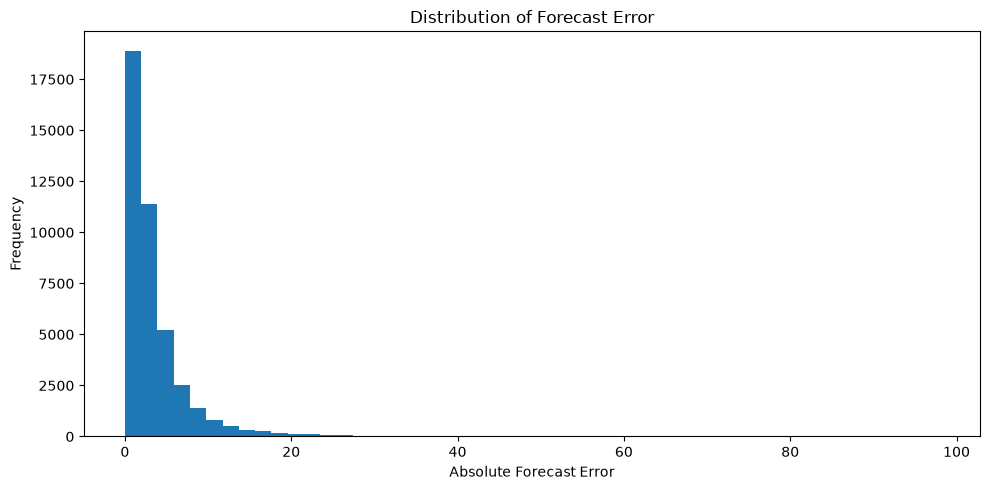

In [47]:
plt.figure(figsize=(10, 5))

plt.hist(
    validation_results["absolute_error"],
    bins=50
)

plt.xlabel("Absolute Forecast Error")
plt.ylabel("Frequency")
plt.title("Distribution of Forecast Error")

plt.tight_layout()
plt.show()

## 3. Product-Store Demand Summary

Inventory decisions are made at the product-store level rather than only at the aggregate level.

For each series, calculate average forecasted demand, forecast uncertainty, average actual demand, and forecast error.

In [8]:
series_summary = (
    validation_results
    .groupby(
        [
            "id",
            "item_id",
            "dept_id",
            "cat_id",
            "store_id",
            "state_id"
        ]
    )
    .agg(
        avg_forecast=("forecast", "mean"),
        avg_actual=("sales", "mean"),
        forecast_error_std=("error", "std"),
        avg_absolute_error=("absolute_error", "mean"),
        max_forecast=("forecast", "max"),
        total_forecast=("forecast", "sum")
    )
    .reset_index()
)

print("Series summary shape:", series_summary.shape)
print(series_summary.head())

Series summary shape: (1500, 12)
                            id      item_id  dept_id cat_id store_id state_id  \
0  FOODS_1_004_WI_1_validation  FOODS_1_004  FOODS_1  FOODS     WI_1       WI   
1  FOODS_1_004_WI_2_validation  FOODS_1_004  FOODS_1  FOODS     WI_2       WI   
2  FOODS_1_012_CA_2_validation  FOODS_1_012  FOODS_1  FOODS     CA_2       CA   
3  FOODS_1_018_CA_1_validation  FOODS_1_018  FOODS_1  FOODS     CA_1       CA   
4  FOODS_1_018_CA_2_validation  FOODS_1_018  FOODS_1  FOODS     CA_2       CA   

   avg_forecast  avg_actual  forecast_error_std  avg_absolute_error  \
0      0.354422    0.000000            0.130194            0.354422   
1      0.399658    0.000000            0.190064            0.399658   
2     14.163149   14.571429            7.695139            6.179765   
3      9.551184    8.321429            5.296807            4.346239   
4     13.142341   13.607143            5.486191            4.505026   

   max_forecast  total_forecast  
0      0.672801    

In [9]:
print(
    series_summary[
        [
            "avg_forecast",
            "avg_actual",
            "forecast_error_std",
            "avg_absolute_error"
        ]
    ].describe()
)

       avg_forecast   avg_actual  forecast_error_std  avg_absolute_error
count   1500.000000  1500.000000         1500.000000         1500.000000
mean       8.014756     7.930810            4.599705            3.504094
std        9.430801     9.549920            3.495170            2.558786
min        0.002003     0.000000            0.004583            0.002003
25%        2.715527     2.598214            2.349432            1.874588
50%        5.017367     4.982143            3.747504            2.875161
75%        9.462987     9.178571            5.632875            4.306332
max      115.087260   110.357143           32.044333           22.128975


## 4. Inventory Planning Assumptions

Because actual replenishment data is unavailable, the inventory analysis uses the following planning assumptions:

- Lead time: 7 days
- Target service level: 95%
- Z-score for 95% service level: 1.645
- Demand during lead time is based on average forecasted daily demand
- Safety stock is based on forecast error variability

These assumptions are illustrative and can be adjusted for different inventory policies.

In [10]:
lead_time_days = 7
service_level = 0.95
z_score = 1.645

print("Lead time:", lead_time_days, "days")
print("Service level:", service_level)
print("Z-score:", z_score)

Lead time: 7 days
Service level: 0.95
Z-score: 1.645


## 5. Safety Stock

Safety stock provides a buffer against forecast uncertainty.

Using forecast error variability, safety stock is estimated as:

**Safety Stock = Z × Forecast Error Standard Deviation × √Lead Time**

This represents additional inventory intended to protect against demand uncertainty during the replenishment period.

In [11]:
series_summary["safety_stock"] = (
    z_score
    * series_summary["forecast_error_std"]
    * np.sqrt(lead_time_days)
)

print(
    series_summary[
        [
            "id",
            "avg_forecast",
            "forecast_error_std",
            "safety_stock"
        ]
    ].head()
)

                            id  avg_forecast  forecast_error_std  safety_stock
0  FOODS_1_004_WI_1_validation      0.354422            0.130194      0.566637
1  FOODS_1_004_WI_2_validation      0.399658            0.190064      0.827207
2  FOODS_1_012_CA_2_validation     14.163149            7.695139     33.491253
3  FOODS_1_018_CA_1_validation      9.551184            5.296807     23.053086
4  FOODS_1_018_CA_2_validation     13.142341            5.486191     23.877334


## 6. Reorder Point

The reorder point estimates the inventory position at which replenishment should be initiated.

**Reorder Point = Expected Lead-Time Demand + Safety Stock**

Expected lead-time demand is estimated using the average daily forecast multiplied by the assumed lead time.

In [12]:
series_summary["lead_time_demand"] = (
    series_summary["avg_forecast"]
    * lead_time_days
)

series_summary["reorder_point"] = (
    series_summary["lead_time_demand"]
    + series_summary["safety_stock"]
)

print(
    series_summary[
        [
            "id",
            "lead_time_demand",
            "safety_stock",
            "reorder_point"
        ]
    ].head()
)

                            id  lead_time_demand  safety_stock  reorder_point
0  FOODS_1_004_WI_1_validation          2.480955      0.566637       3.047592
1  FOODS_1_004_WI_2_validation          2.797609      0.827207       3.624816
2  FOODS_1_012_CA_2_validation         99.142045     33.491253     132.633298
3  FOODS_1_018_CA_1_validation         66.858285     23.053086      89.911372
4  FOODS_1_018_CA_2_validation         91.996386     23.877334     115.873720


## 7. Inventory Risk and Priority

Actual stockout risk cannot be calculated because the dataset does not contain on-hand inventory or replenishment records.

Instead, a planning priority score is created using forecasted demand and forecast uncertainty. Products with higher expected demand and greater forecast uncertainty receive higher priority for inventory review.

This score is intended as a prioritization tool rather than a probability of stockout.

In [13]:
series_summary["demand_score"] = (
    series_summary["avg_forecast"]
    / series_summary["avg_forecast"].max()
)

series_summary["uncertainty_score"] = (
    series_summary["forecast_error_std"]
    / series_summary["forecast_error_std"].max()
)

series_summary["inventory_priority_score"] = (
    series_summary["demand_score"]
    * series_summary["uncertainty_score"]
)

print(
    series_summary[
        [
            "id",
            "avg_forecast",
            "forecast_error_std",
            "demand_score",
            "uncertainty_score",
            "inventory_priority_score"
        ]
    ].head()
)

                            id  avg_forecast  forecast_error_std  \
0  FOODS_1_004_WI_1_validation      0.354422            0.130194   
1  FOODS_1_004_WI_2_validation      0.399658            0.190064   
2  FOODS_1_012_CA_2_validation     14.163149            7.695139   
3  FOODS_1_018_CA_1_validation      9.551184            5.296807   
4  FOODS_1_018_CA_2_validation     13.142341            5.486191   

   demand_score  uncertainty_score  inventory_priority_score  
0      0.003080           0.004063                  0.000013  
1      0.003473           0.005931                  0.000021  
2      0.123064           0.240140                  0.029553  
3      0.082991           0.165296                  0.013718  
4      0.114195           0.171206                  0.019551  


## 8. Highest-Priority Product-Store Series

The highest-priority series are those combining meaningful forecasted demand with relatively high forecast uncertainty.

These products would be candidates for closer inventory monitoring under the simulated planning framework.

In [14]:
priority_items = (
    series_summary
    .sort_values(
        "inventory_priority_score",
        ascending=False
    )
    .head(20)
)

print(
    priority_items[
        [
            "id",
            "item_id",
            "store_id",
            "cat_id",
            "avg_forecast",
            "forecast_error_std",
            "safety_stock",
            "reorder_point",
            "inventory_priority_score"
        ]
    ]
)

                              id      item_id store_id cat_id  avg_forecast  \
111  FOODS_3_090_CA_3_validation  FOODS_3_090     CA_3  FOODS    115.087260   
118  FOODS_3_090_WI_3_validation  FOODS_3_090     WI_3  FOODS     76.670959   
80   FOODS_2_360_WI_2_validation  FOODS_2_360     WI_2  FOODS     52.194969   
137  FOODS_3_120_CA_3_validation  FOODS_3_120     CA_3  FOODS     65.005973   
96   FOODS_3_070_WI_2_validation  FOODS_3_070     WI_2  FOODS     37.205509   
114  FOODS_3_090_TX_2_validation  FOODS_3_090     TX_2  FOODS     64.246869   
135  FOODS_3_120_CA_1_validation  FOODS_3_120     CA_1  FOODS     37.718359   
115  FOODS_3_090_TX_3_validation  FOODS_3_090     TX_3  FOODS     62.482416   
109  FOODS_3_090_CA_1_validation  FOODS_3_090     CA_1  FOODS     53.437201   
364  FOODS_3_586_TX_2_validation  FOODS_3_586     TX_2  FOODS     79.302596   
363  FOODS_3_586_TX_1_validation  FOODS_3_586     TX_1  FOODS     53.450830   
406  FOODS_3_681_WI_3_validation  FOODS_3_681     WI

### Highest Reorder Points

Products with higher reorder points require greater inventory coverage under the assumed seven-day lead time and 95% service level.

In [15]:
top_reorder_points = (
    series_summary
    .sort_values(
        "reorder_point",
        ascending=False
    )
    .head(15)
)

print(
    top_reorder_points[
        [
            "id",
            "item_id",
            "store_id",
            "avg_forecast",
            "lead_time_demand",
            "safety_stock",
            "reorder_point"
        ]
    ]
)

                              id      item_id store_id  avg_forecast  \
111  FOODS_3_090_CA_3_validation  FOODS_3_090     CA_3    115.087260   
118  FOODS_3_090_WI_3_validation  FOODS_3_090     WI_3     76.670959   
364  FOODS_3_586_TX_2_validation  FOODS_3_586     TX_2     79.302596   
137  FOODS_3_120_CA_3_validation  FOODS_3_120     CA_3     65.005973   
114  FOODS_3_090_TX_2_validation  FOODS_3_090     TX_2     64.246869   
361  FOODS_3_586_CA_3_validation  FOODS_3_586     CA_3     67.331953   
115  FOODS_3_090_TX_3_validation  FOODS_3_090     TX_3     62.482416   
80   FOODS_2_360_WI_2_validation  FOODS_2_360     WI_2     52.194969   
365  FOODS_3_586_TX_3_validation  FOODS_3_586     TX_3     61.662613   
109  FOODS_3_090_CA_1_validation  FOODS_3_090     CA_1     53.437201   
363  FOODS_3_586_TX_1_validation  FOODS_3_586     TX_1     53.450830   
113  FOODS_3_090_TX_1_validation  FOODS_3_090     TX_1     54.412535   
25   FOODS_1_096_WI_2_validation  FOODS_1_096     WI_2     53.22

## 9. Safety Stock Analysis

Safety stock varies across product-store combinations because forecast uncertainty differs across series.

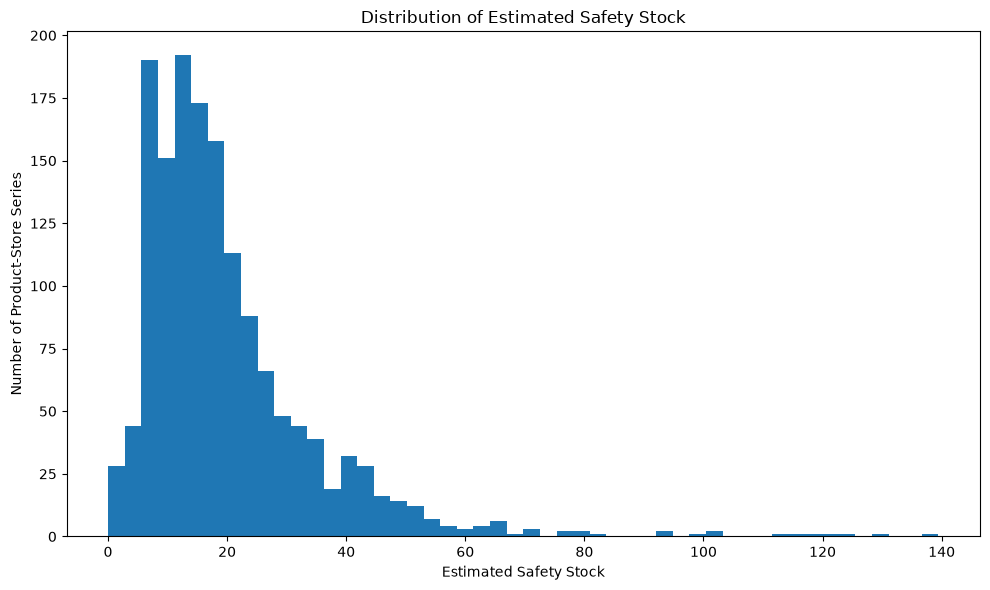

In [16]:
plt.figure(figsize=(10, 6))

plt.hist(
    series_summary["safety_stock"],
    bins=50
)

plt.xlabel("Estimated Safety Stock")
plt.ylabel("Number of Product-Store Series")
plt.title("Distribution of Estimated Safety Stock")

plt.tight_layout()
plt.show()

## 10. Store-Level Inventory Priorities

Inventory requirements can also be summarized at the store level to identify locations with greater forecasted demand and inventory requirements.

In [17]:
priority_threshold = (
    series_summary["inventory_priority_score"]
    .quantile(0.90)
)

In [18]:
store_summary = (
    series_summary
    .groupby("store_id")
    .agg(
        total_forecast=("total_forecast", "sum"),
        total_safety_stock=("safety_stock", "sum"),
        total_reorder_point=("reorder_point", "sum"),
        avg_forecast_error=("forecast_error_std", "mean"),
        high_priority_series=(
            "inventory_priority_score",
            lambda x: (x >= x.quantile(0.90)).sum()
        )
    )
    .reset_index()
    .sort_values(
        "total_forecast",
        ascending=False
    )
)

print(store_summary)

  store_id  total_forecast  total_safety_stock  total_reorder_point  \
2     CA_3    53475.975156         4257.267060         17626.260849   
8     WI_2    44999.272940         4359.630868         15609.449103   
0     CA_1    36029.562747         3301.746526         12309.137213   
9     WI_3    35206.698291         3069.915617         11871.590190   
5     TX_2    34271.068098         2690.905782         11258.672806   
6     TX_3    32940.621528         2640.793591         10875.948973   
4     TX_1    29848.387233         2613.363498         10075.460307   
1     CA_2    27446.117068         2631.726946          9493.256213   
7     WI_1    24404.334556         2373.719060          8474.802699   
3     CA_4    17997.713980         2089.607981          6589.036476   

   avg_forecast_error  high_priority_series  
2            6.521158                    15  
8            6.677956                    15  
0            5.057519                    15  
9            4.702407             

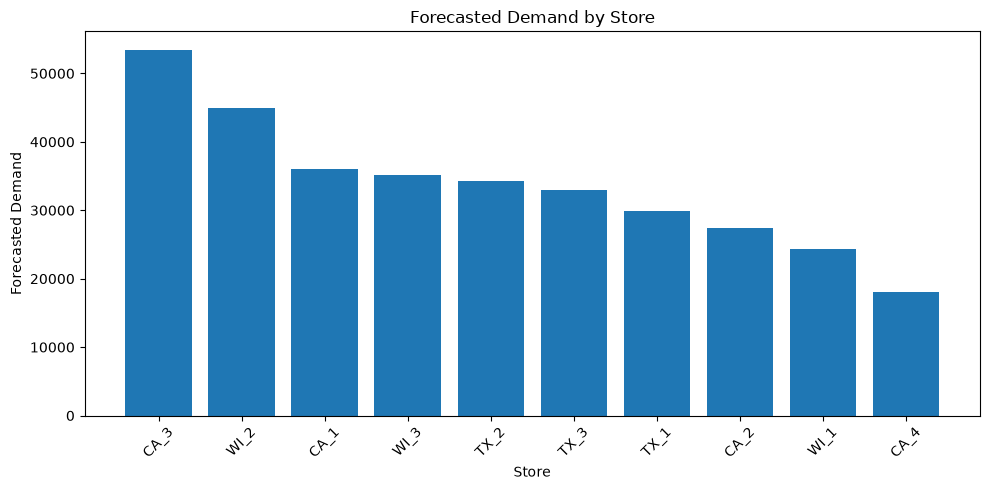

In [19]:
plt.figure(figsize=(10, 5))

plt.bar(
    store_summary["store_id"],
    store_summary["total_forecast"]
)

plt.xlabel("Store")
plt.ylabel("Forecasted Demand")
plt.title("Forecasted Demand by Store")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 11. Inventory Planning Recommendations

The forecast-driven inventory analysis supports several practical planning actions:

- Prioritize high-demand, high-uncertainty product-store combinations for inventory review.
- Use estimated safety stock to provide additional protection against forecast error.
- Use reorder points to determine when replenishment should be initiated under the assumed lead time.
- Monitor stores with high aggregate forecasted demand and large inventory requirements.
- Recalculate inventory parameters as forecasts and demand patterns change.

These recommendations are based on simulated inventory assumptions because actual on-hand inventory, lead times, and replenishment history are not available in the dataset.

In [20]:
inventory_results = series_summary[
    [
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id",
        "avg_forecast",
        "forecast_error_std",
        "lead_time_demand",
        "safety_stock",
        "reorder_point",
        "uncertainty_score",
        "inventory_priority_score"
    ]
].copy()

print("Shape:", inventory_results.shape)
print(inventory_results.head())

Shape: (1500, 13)
                            id      item_id  dept_id cat_id store_id state_id  \
0  FOODS_1_004_WI_1_validation  FOODS_1_004  FOODS_1  FOODS     WI_1       WI   
1  FOODS_1_004_WI_2_validation  FOODS_1_004  FOODS_1  FOODS     WI_2       WI   
2  FOODS_1_012_CA_2_validation  FOODS_1_012  FOODS_1  FOODS     CA_2       CA   
3  FOODS_1_018_CA_1_validation  FOODS_1_018  FOODS_1  FOODS     CA_1       CA   
4  FOODS_1_018_CA_2_validation  FOODS_1_018  FOODS_1  FOODS     CA_2       CA   

   avg_forecast  forecast_error_std  lead_time_demand  safety_stock  \
0      0.354422            0.130194          2.480955      0.566637   
1      0.399658            0.190064          2.797609      0.827207   
2     14.163149            7.695139         99.142045     33.491253   
3      9.551184            5.296807         66.858285     23.053086   
4     13.142341            5.486191         91.996386     23.877334   

   reorder_point  uncertainty_score  inventory_priority_score  
0   

## 12. Export Inventory Analytics

The final inventory planning dataset is exported for use in the project dashboard and downstream analysis.

In [21]:
inventory_results.to_csv(
    "../data/processed/inventory_analysis.csv",
    index=False
)

store_summary.to_csv(
    "../data/processed/store_inventory_summary.csv",
    index=False
)

print("Inventory analysis files saved.")

Inventory analysis files saved.


## 13. Inventory Analytics Findings

### Forecast-Based Planning

The LightGBM forecasts provide a foundation for translating predicted demand into inventory planning metrics.

### Safety Stock

Safety stock varies across product-store combinations because forecast uncertainty differs across series. Higher forecast uncertainty requires a larger buffer to maintain the assumed service level.

### Reorder Points

Reorder points combine expected seven-day demand with estimated safety stock, providing a forecast-driven threshold for replenishment planning.

### Inventory Prioritization

Products with both higher expected demand and greater forecast uncertainty receive higher inventory priority. These products represent candidates for closer monitoring under the simulated planning framework.

### Business Implication

The analysis demonstrates how demand forecasting can support downstream inventory decisions rather than stopping at model accuracy. Forecasts can be translated into operational metrics that help prioritize inventory attention across products and stores.

### Limitations

The inventory analysis is a planning simulation rather than an evaluation of actual inventory performance. The dataset does not contain on-hand inventory, supplier lead times, purchase orders, replenishment quantities, or observed stockouts. The seven-day lead time and 95% service level are therefore explicit assumptions that can be adjusted for different planning scenarios.

## 14. Lead Time & Service Level Sensitivity Analysis

Inventory requirements depend on both replenishment lead time and the target service level.

To evaluate the effect of these planning assumptions, four lead times (3, 7, 14, and 21 days) and three target service levels (90%, 95%, and 99%) are tested.

Each combination is evaluated while keeping the underlying demand forecasts and forecast uncertainty unchanged.

The analysis evaluates how lead-time demand, safety stock, and reorder points change across the planning assumptions.

In [22]:
lead_times = [3, 7, 14, 21]

service_levels = {
    0.90: 1.282,
    0.95: 1.645,
    0.99: 2.326
}

print("Lead times:", lead_times)
print("Service levels:", list(service_levels.keys()))

Lead times: [3, 7, 14, 21]
Service levels: [0.9, 0.95, 0.99]


### Sensitivity Calculations

For each combination of lead time and service level, lead-time demand, safety stock, and reorder point are recalculated using the existing forecast and forecast error estimates.

In [23]:
import numpy as np

scenarios = []

for lead_time in lead_times:
    for service_level, z in service_levels.items():

        scenario = inventory_results[
            [
                "id",
                "item_id",
                "dept_id",
                "cat_id",
                "store_id",
                "state_id",
                "avg_forecast",
                "forecast_error_std"
            ]
        ].copy()

        scenario["lead_time"] = lead_time
        scenario["service_level"] = service_level
        scenario["z_score"] = z

        scenario["lead_time_demand"] = (
            scenario["avg_forecast"] * lead_time
        )

        scenario["safety_stock"] = (
            z
            * scenario["forecast_error_std"]
            * np.sqrt(lead_time)
        )

        scenario["reorder_point"] = (
            scenario["lead_time_demand"]
            + scenario["safety_stock"]
        )

        scenarios.append(scenario)

sensitivity_results = pd.concat(
    scenarios,
    ignore_index=True
)

print("Sensitivity results shape:", sensitivity_results.shape)

Sensitivity results shape: (18000, 14)


### Sensitivity Scenario Validation

The sensitivity dataset is checked to ensure that all lead-time and service-level combinations were generated correctly.

In [24]:
scenario_check = (
    sensitivity_results[
        ["lead_time", "service_level", "z_score"]
    ]
    .drop_duplicates()
    .sort_values(["lead_time", "service_level"])
)

scenario_check

,lead_time,service_level,z_score
0,3,0.90,1.282
1500,3,0.95,1.645
3000,3,0.99,2.326
4500,7,0.90,1.282
6000,7,0.95,1.645
7500,7,0.99,2.326
9000,14,0.90,1.282
10500,14,0.95,1.645
12000,14,0.99,2.326
13500,21,0.90,1.282


### Sensitivity Summary

The product-store results are aggregated across all 1,500 series to compare average inventory requirements under each planning assumption.

In [30]:
sensitivity_summary = (
    sensitivity_results
    .groupby(["lead_time", "service_level"], as_index=False)
    .agg(
        avg_lead_time_demand=("lead_time_demand", "mean"),
        avg_safety_stock=("safety_stock", "mean"),
        avg_reorder_point=("reorder_point", "mean")
    )
    .sort_values(["lead_time", "service_level"])
)

sensitivity_summary.round(2)

,lead_time,service_level,avg_lead_time_demand,avg_safety_stock,avg_reorder_point
0,3,0.90,24.04,10.21,34.26
1,3,0.95,24.04,13.11,37.15
2,3,0.99,24.04,18.53,42.58
3,7,0.90,56.10,15.60,71.70
4,7,0.95,56.10,20.02,76.12
5,7,0.99,56.10,28.31,84.41
6,14,0.90,112.21,22.06,134.27
7,14,0.95,112.21,28.31,140.52
8,14,0.99,112.21,40.03,152.24
9,21,0.90,168.31,27.02,195.33


### Base Case Validation

The original inventory analysis uses a seven-day lead time and 95% service level.

The corresponding sensitivity-analysis results are checked against the original inventory calculations to verify that the base case remains consistent.

In [31]:
original_avg = inventory_results[
    ["safety_stock", "reorder_point"]
].mean()

sensitivity_base = sensitivity_summary[
    (sensitivity_summary["lead_time"] == 7) &
    (sensitivity_summary["service_level"] == 0.95)
].iloc[0]

print("Original average safety stock:",
      original_avg["safety_stock"])

print("Sensitivity average safety stock:",
      sensitivity_base["avg_safety_stock"])

print()

print("Original average reorder point:",
      original_avg["reorder_point"])

print("Sensitivity average reorder point:",
      sensitivity_base["avg_reorder_point"])

Original average safety stock: 20.0191179521689
Sensitivity average safety stock: 20.0191179521689

Original average reorder point: 76.12240988496609
Sensitivity average reorder point: 76.12240988496609


### Sensitivity Analysis Findings

Increasing lead time increases expected lead-time demand and therefore increases the reorder point.

Increasing the target service level increases the safety-stock buffer because a larger Z-score is applied to forecast uncertainty.

The results demonstrate that inventory requirements are sensitive to both replenishment timing and the desired level of protection against forecast uncertainty.

The seven-day lead time and 95% service level represent the base planning case used in the original inventory analysis.

## 15. Export Sensitivity Analysis

The sensitivity results are exported for use in Tableau and downstream analysis.

In [32]:
tableau_sensitivity = sensitivity_summary.copy()

tableau_sensitivity["service_level_pct"] = (
    tableau_sensitivity["service_level"] * 100
)

tableau_sensitivity = tableau_sensitivity.drop(
    columns=["service_level"]
)

tableau_sensitivity

,lead_time,avg_lead_time_demand,avg_safety_stock,avg_reorder_point,service_level_pct
0,3,24.044268,10.213596,34.257864,90.0
1,3,24.044268,13.105589,37.149857,95.0
2,3,24.044268,18.531064,42.575332,99.0
3,7,56.103292,15.601525,71.704817,90.0
4,7,56.103292,20.019118,76.122410,95.0
5,7,56.103292,28.306668,84.409960,99.0
6,14,112.206584,22.063889,134.270473,90.0
7,14,112.206584,28.311308,140.517892,95.0
8,14,112.206584,40.031673,152.238257,99.0
9,21,168.309876,27.022635,195.332510,90.0


In [33]:
tableau_sensitivity.to_csv(
    "../data/processed/inventory_sensitivity.csv",
    index=False
)

print("Exported sensitivity analysis.")

Exported sensitivity analysis.
